# Stackelberg quantity leadership

The leader commits a quantity. The follower then **observes that actual commitment** and chooses its quantity. Both actors use the reusable LLM policy; a separate analytical solver supplies the backward-induction benchmark.

$$P(Q)=\max(a-bQ,0),\quad Q=q_L+q_F,\quad \pi_i=(P(Q)-c_i)q_i.$$

For nonnegative constant costs, the benchmark follower strategy is
$$q_F^*(q_L)=\operatorname{clip}\left(\frac{a-c_F-bq_L}{2b},\underline q_F,\overline q_F\right).$$
The solver maximizes the leader's profit along that response curve, including bounds and zero-price branches. With equal costs and nonbinding bounds, $q_L^*=(a-c)/(2b)$ and $q_F^*=(a-c)/(4b)$.

A single observed LLM trajectory is a pair of actions, not a complete contingent strategy or proof of subgame perfection. See [Yale's Stackelberg lecture](https://oyc.yale.edu/economics/econ-159/lecture-14) for the textbook timing.

**Live mode is enabled.** Re-execution makes bounded calls using `.env` (`API_KEY`, `MODEL`). Switch to fake mode for offline verification; its actions are explicitly configured test fixtures. Every committed action includes a brief stated explanation, not private internal reasoning.


In [1]:
import json
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

from examples.stackelberg import QuantityFirmInput, StackelbergInputs, run_job, run_live_job
from components.common.economics.models import LinearInverseDemand
from components.mechanisms.stackelberg import QuantityDomain, StackelbergGameView, StackelbergMechanism
from simulation_core.logging import replay, stream_action_trace


## Editable user inputs

Replace the illustrative values, then change `INPUT_SOURCE` to `"user"`. The same Pydantic schema accepts user JSON in memory. Quantity bounds and costs may differ by firm. `max_steps=1` demonstrates a partial run with only a leader commitment; it produces no invented follower choice or market payoff.


In [2]:
INPUT_SOURCE = "illustrative"
INPUTS = StackelbergInputs(
    demand=LinearInverseDemand(a=100.0, b=1.0),
    leader=QuantityFirmInput(id="Leader", marginal_cost=20.0,
                             quantity_domain=QuantityDomain(lower=0.0, upper=100.0)),
    follower=QuantityFirmInput(id="Follower", marginal_cost=20.0,
                               quantity_domain=QuantityDomain(lower=0.0, upper=100.0)),
    max_steps=2,
)
# Alternatively: INPUTS = StackelbergInputs.model_validate_json(Path("your_inputs.json").read_text())
assert StackelbergInputs.model_validate_json(INPUTS.model_dump_json()) == INPUTS
print("Input source:", INPUT_SOURCE)
print(INPUTS.model_dump_json(indent=2))


Input source: illustrative
{
  "demand": {
    "a": 100.0,
    "b": 1.0
  },
  "leader": {
    "id": "Leader",
    "marginal_cost": 20.0,
    "quantity_domain": {
      "lower": 0.0,
      "upper": 100.0
    },
    "persona": ""
  },
  "follower": {
    "id": "Follower",
    "marginal_cost": 20.0,
    "quantity_domain": {
      "lower": 0.0,
      "upper": 100.0
    },
    "persona": ""
  },
  "max_steps": 2
}


## Sequential primary simulation

The generic phase schedule activates only the leader in stage 1 and only the follower in stage 2. Trusted observation projection applies phase-specific permissions. Neither actor receives the mathematical solution or another actor's private state. The first commitment is irreversible; profits are realized after the second commitment.


In [3]:
USE_LIVE_API = True
with stream_action_trace():
    artifact = (run_live_job(INPUTS, input_source=INPUT_SOURCE) if USE_LIVE_API
                else run_job(INPUTS, input_source=INPUT_SOURCE))
config, result, report = artifact.manifest.simulation, artifact.result, artifact.benchmark
assert report is not None
leader, follower = INPUTS.leader.id, INPUTS.follower.id
actor_ids = (leader, follower)
quantities = {action.actor_id: action.payload["quantity"] for action in report.observed_actions}
print("Mode:", "LIVE MODEL" if USE_LIVE_API else "FAKE GATEWAY — deterministic fixture")
print("Primary status:", result.status)
print("Benchmark:", report.result.solution_concept, report.result.status)
print("Comparison:", report.comparison_status, "| action source ticks:", report.observed_source_ticks)


{"tick": 1, "actor_id": "Leader", "action": {"actor_id": "Leader", "kind": "set_quantity", "payload": {"quantity": 40.0}}, "rationale": "Market P=100-Q, c=20 both. Follower best response is (80-qL)/2. Leader profit then (80-qL)/2*qL maximized at qL=40. Assume follower plays profit-maximizing response."}


{"tick": 2, "actor_id": "Follower", "action": {"actor_id": "Follower", "kind": "set_quantity", "payload": {"quantity": 20.0}}, "rationale": "Observed Leader committed 40. With P=100-Q and cost 20, my profit is (40-qf)*qf, maximized at qf=20 within [0,100]."}


Mode: LIVE MODEL
Primary status: completed
Benchmark: subgame_perfect solved
Comparison: complete | action source ticks: {'Leader': 1, 'Follower': 2}


## What happened, and what each actor knew

Event snapshots store the state **after** a commit, so their phase identifies the next decision stage. The table distinguishes this from the stage in which the recorded action was chosen. Observation summaries show only public field names and prior commitments; private prompts and facts remain inside the internal artifact.


In [4]:
rows = ["| Tick | Decision stage | Actor | Quantity | Next phase | Realized payoffs |",
        "|---:|---|---|---:|---|---|"]
for previous, event in zip(result.events, result.events[1:]):
    for action in event.actions:
        rows.append(f"| {event.state.tick} | {previous.state.phase} | {action.actor_id} | "
                    f"{action.payload['quantity']:g} | {event.state.phase} | {event.outcome.payoffs} |")
display(Markdown("\n".join(rows)))
for call in result.model_calls:
    if call.status == "accepted":
        observation = json.loads(call.request["input_json"])["observation"]
        print(call.actor_id, "phase:", observation["phase"],
              "public fields:", list(observation["visible"]),
              "observed commitments:", observation["visible"].get("commitments", {}))


| Tick | Decision stage | Actor | Quantity | Next phase | Realized payoffs |
|---:|---|---|---:|---|---|
| 1 | leader_commit | Leader | 40 | follower_response | {} |
| 2 | follower_response | Follower | 20 | finished | {'Leader': 800.0, 'Follower': 400.0} |

Leader phase: leader_commit public fields: ['market'] observed commitments: {}
Follower phase: follower_response public fields: ['market', 'commitments'] observed commitments: {'Leader': 40.0}


## Observed actions versus the backward-induction outcome

Deltas are **actor outcome minus benchmark outcome**. All analytic maximizing candidates found are retained; a selected index below only controls the plot. Continuous zero-profit ties are reported as intervals in the diagnostics.


In [5]:
complete = report.comparison_status == "complete"
observed = result.outcomes[-1] if complete else None
if complete and report.result.equilibria:
    rows = ["| Reference | Actor | LLM quantity | Benchmark quantity | Quantity delta | LLM profit | Benchmark profit |",
            "|---:|---|---:|---:|---:|---:|---:|"]
    for comparison in report.comparisons:
        equilibrium = report.result.equilibria[comparison.equilibrium_index]
        reference = {a.actor_id: a.payload["quantity"] for a in equilibrium.actions}
        for aid in actor_ids:
            rows.append(f"| {comparison.equilibrium_index} | {aid} | {quantities[aid]:.5f} | {reference[aid]:.5f} | "
                        f"{comparison.numeric_action_deltas[aid]['quantity']:+.5f} | {observed.payoffs[aid]:.5f} | "
                        f"{equilibrium.outcome.payoffs[aid]:.5f} |")
    display(Markdown("\n".join(rows)))
    print("Observed market price:", observed.metrics["price"])
else:
    print("No complete comparison:", report.comparison_status)
    print("Committed quantities:", quantities)
    print("No follower choice or realized market payoff is fabricated for a partial run.")


| Reference | Actor | LLM quantity | Benchmark quantity | Quantity delta | LLM profit | Benchmark profit |
|---:|---|---:|---:|---:|---:|---:|
| 0 | Leader | 40.00000 | 40.00000 | +0.00000 | 800.00000 | 800.00000 |
| 0 | Follower | 20.00000 | 20.00000 | +0.00000 | 400.00000 | 400.00000 |

Observed market price: 40.0


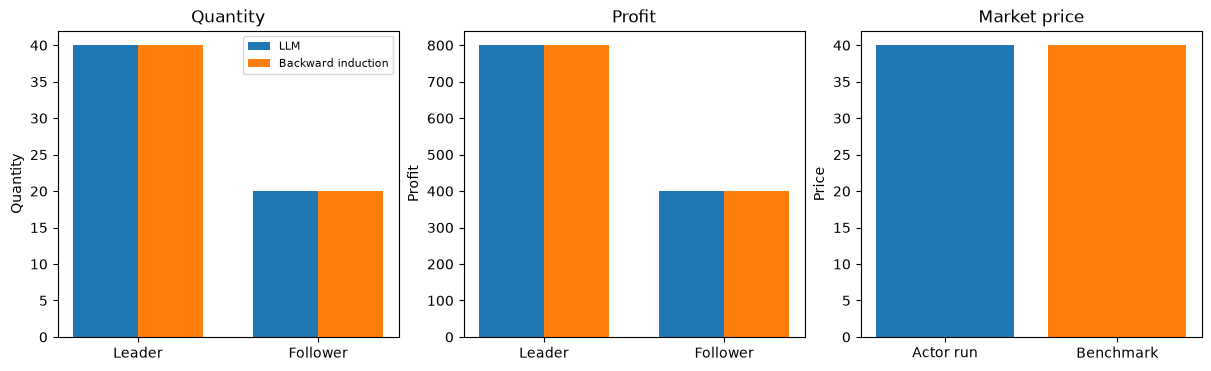

In [6]:
PLOT_REFERENCE_INDEX = 0
if complete and report.result.equilibria:
    equilibrium = report.result.equilibria[PLOT_REFERENCE_INDEX]
    reference = {a.actor_id: a.payload["quantity"] for a in equilibrium.actions}
    fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), constrained_layout=True)
    x = np.arange(2)
    for ax, (title, actual, benchmark) in zip(axes[:2], [
        ("Quantity", quantities, reference), ("Profit", observed.payoffs, equilibrium.outcome.payoffs)
    ]):
        ax.bar(x-.18, [actual[aid] for aid in actor_ids], .36, label="LLM" if USE_LIVE_API else "Fixture")
        ax.bar(x+.18, [benchmark[aid] for aid in actor_ids], .36, label="Backward induction")
        ax.set(xticks=x, xticklabels=actor_ids, title=title, ylabel=title)
        ax.axhline(0, color="black", linewidth=.6)
    axes[0].legend(fontsize=8)
    axes[2].bar(["Actor run", "Benchmark"], [observed.metrics["price"], equilibrium.outcome.metrics["price"]],
                color=["tab:blue", "tab:orange"])
    axes[2].set(title="Market price", ylabel="Price")
    plt.show()


## Response curve and decision quality

The follower's conditional gain holds the **actual leader commitment** fixed. The leader's gain instead compares its commitment with the optimum **along a rational follower-response curve**. Holding the observed follower action fixed would evaluate a different, simultaneous game.

Actual leader profit can exceed the benchmark when the LLM follower responds poorly. The plot and diagnostics distinguish actual profit from the leader's hypothetical profit under a rational continuation. These conditional measures do not recover an LLM follower's unobserved strategy at other commitments.


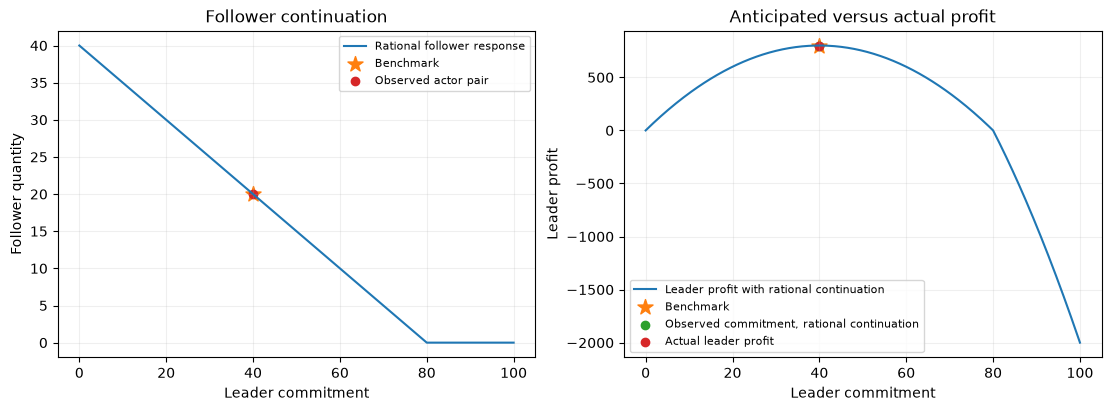

Leader gain: 0.0 | Gain along the rational follower-response curve, relative to the observed leader commitment
Follower gain: 0.0 | Conditional gain with the observed leader commitment held fixed
Strategic diagnostics: {'anticipated_follower_at_observed_commitment': {'actor_id': 'Follower', 'kind': 'set_quantity', 'payload': {'quantity': 20.0}}, 'anticipated_leader_payoff': 800.0, 'actual_leader_payoff': 800.0, 'optimal_anticipated_leader_payoff': 800.0, 'qualification': 'One observed follower action does not identify its full strategy; leader gain assumes the benchmark continuation.'}


In [7]:
if report.result.equilibria:
    game = StackelbergGameView(config, result.events[0].state, StackelbergMechanism())
    domain = INPUTS.leader.quantity_domain
    grid = np.linspace(domain.lower, domain.upper, 401)
    replies, profits = [], []
    for quantity in grid:
        action = game.quantity_action(leader, float(quantity))
        reply = game.follower_response(action)
        replies.append(reply.payload["quantity"])
        profits.append(game.evaluate((action, reply)).payoffs[leader])
    equilibrium = report.result.equilibria[PLOT_REFERENCE_INDEX]
    reference = {a.actor_id: a.payload["quantity"] for a in equilibrium.actions}
    fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
    axes[0].plot(grid, replies, label="Rational follower response")
    axes[0].scatter(reference[leader], reference[follower], marker="*", s=130, color="tab:orange", label="Benchmark")
    axes[1].plot(grid, profits, label="Leader profit with rational continuation")
    axes[1].scatter(reference[leader], equilibrium.outcome.payoffs[leader], marker="*", s=130,
                    color="tab:orange", label="Benchmark")
    if complete:
        diagnostics = report.strategic_diagnostics
        axes[0].scatter(quantities[leader], quantities[follower], color="tab:red", label="Observed actor pair")
        axes[1].scatter(quantities[leader], diagnostics["anticipated_leader_payoff"],
                        color="tab:green", label="Observed commitment, rational continuation")
        axes[1].scatter(quantities[leader], observed.payoffs[leader], color="tab:red", label="Actual leader profit")
    axes[0].set(xlabel="Leader commitment", ylabel="Follower quantity", title="Follower continuation")
    axes[1].set(xlabel="Leader commitment", ylabel="Leader profit", title="Anticipated versus actual profit")
    for ax in axes:
        ax.legend(fontsize=8)
        ax.grid(alpha=.2)
    plt.show()
if complete:
    for aid in actor_ids:
        print(aid, "gain:", report.observed_regrets.get(aid), "|", report.deviation_interpretations.get(aid))
    print("Strategic diagnostics:", report.strategic_diagnostics)


## Stated explanations for every committed action

These are the actors' returned explanations. They may contain beliefs or assumptions about the other firm's behavior; a leader's prediction is not an observation of a future follower action.


In [8]:
for event in result.events:
    for decision in event.decisions:
        print(f"Tick {event.state.tick} | {decision.action.actor_id} | Quantity {decision.action.payload['quantity']:g}")
        print("Stated rationale:", decision.rationale, "\n")
        assert decision.rationale


Tick 1 | Leader | Quantity 40
Stated rationale: Market P=100-Q, c=20 both. Follower best response is (80-qL)/2. Leader profit then (80-qL)/2*qL maximized at qL=40. Assume follower plays profit-maximizing response. 

Tick 2 | Follower | Quantity 20
Stated rationale: Observed Leader committed 40. With P=100-Q and cost 20, my profit is (40-qf)*qf, maximized at qf=20 within [0,100]. 



## Call provenance, benchmark scope, and replay

The benchmark uses piecewise quadratic optimization with bounded follower responses. Nonnegative constant costs, truncated linear inverse demand, two firms, and fixed minimum-quantity tie-breaking are explicit scope restrictions. Alternative follower choices on zero-profit ties can support other strategies; diagnostics describe that limitation.

The event log is the canonical record for reconstructing committed states. Replay uses saved snapshots and never calls the model. Temporary JSON job manifests are removed by the job runner; the returned artifact retains the resolved configuration and assumptions for audit.


In [9]:
rows = ["| Actor | Mode | Model | Attempt | Status | Input tokens | Output tokens |",
        "|---|---|---|---:|---|---:|---:|"]
for call in result.model_calls:
    rows.append(f"| {call.actor_id} | {call.mode} | {call.response_model or call.model} | {call.attempt} | "
                f"{call.status} | {call.input_tokens} | {call.output_tokens} |")
display(Markdown("\n".join(rows)))
assert replay(result.events)[-1] == result.final_state
assert type(artifact).model_validate_json(artifact.model_dump_json()) == artifact
assert result.events[1].outcome.payoffs == {}
if complete:
    assert report.observed_source_ticks == {leader: 1, follower: 2}
print("Replay, JSON roundtrip, delayed market clearing, and stage provenance verified.")
print("Analytical certification:", report.result.certification)
print("Benchmark diagnostics:", report.result.diagnostics)
print("Config SHA-256:", report.config_sha256)


| Actor | Mode | Model | Attempt | Status | Input tokens | Output tokens |
|---|---|---|---:|---|---:|---:|
| Leader | live | muse-spark-1.3-contributor | 1 | accepted | 770 | 278 |
| Follower | live | muse-spark-1.3-contributor | 1 | accepted | 783 | 217 |

Replay, JSON roundtrip, delayed market clearing, and stage provenance verified.
Analytical certification: analytic
Benchmark diagnostics: {'method': 'Piecewise quadratic leader optimization along the bounded follower best-response curve', 'payoff_tolerance': 1e-09, 'follower_strategy': 'clip((a-c_F-b*q_L)/(2*b), follower_lower, follower_upper); choose smallest quantity on zero-profit ties', 'leader_bounds': {'lower': 0.0, 'upper': 100.0}, 'follower_bounds': {'lower': 0.0, 'upper': 100.0}, 'candidate_leader_quantities': [0.0, 40.0, 80.0, 100.0], 'optimal_leader_intervals': [], 'candidate_payoffs': [{'quantity': 0.0, 'leader_profit': 0.0, 'follower_quantity': 40.0}, {'quantity': 40.0, 'leader_profit': 800.0, 'follower_quantity': 20.0}, {'quantity': 80.0, 'leader_profit': 0.0, 'follower_quantity': 0.0}, {'quantity': 100.0, 'leader_profit': -2000.0, 'follower_quantity': 0.0}], 'scope': 'Single two-firm quantity game, truncated linear inverse demand, nonnegative constant costs, bounded comm

## Assumptions and input provenance

Illustrative values are synthetic, not empirical estimates. Common market data and costs are public in this example; private memory remains actor-specific. Every active actor acts once per stage. There is one leader-follower episode, with no subsequent price or quantity revision.


In [10]:
for assumption in result.assumptions:
    print(f"[{assumption.source}] {assumption.path}: {assumption.rationale}")
print("Mapped user inputs:", [item.name for item in artifact.manifest.request.supplied_inputs])


[default] /world/parameters: Explicit linear inverse demand, nonnegative constant marginal costs and quantity bounds. Illustrative values are synthetic, not calibrated.
[textbook] /world/initial_public_state/market: Two-firm Stackelberg quantity leadership: first commitment is irrevocable and the follower observes it before acting. Price is truncated at zero.
[default] /phase_permissions: Leader sees market data; follower additionally sees the actual committed leader quantity. Neither receives the other's private state.
[default] /benchmark: Backward induction assumes the follower maximizes profit at every commitment; zero-profit ties select the smallest feasible follower quantity. Leader deviation gains compare rational continuations, not the observed follower quantity held fixed. One observed follower action does not reveal its full strategy.
Mapped user inputs: []
